# Case Study: Forecasting Bitcoin Volatility
**GARCH, Realized Variance and Out-of-Sample Risk Forecasting — Predictive Statistics in Finance**

This notebook answers every task of the case (Parts I–VII). Each code cell is followed by a short
explanation of *what the code does* and *what the result means*.

**Roadmap**
| Part | Question | Tasks |
|---|---|---|
| I | Is there volatility to forecast? | 1 |
| II | ARCH vs GARCH: what do the dynamics mean? | 2 |
| III | Normal vs Student-t innovations | 3 |
| IV | Expanding-window GARCH-t forecasts vs realized variance | 4 |
| V | Simple RV-OLS benchmark | 5 |
| VI | Two-year rolling window & parameter stability | 6 |
| VII | Recommendation | – |

**Timing convention (critical).** Everything is "pseudo-out-of-sample": a forecast for day *t+1* only
uses information up to day *t*. Training sample = up to 31 Dec 2024; OOS = 1 Jan 2025 – 31 Aug 2026.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from arch import arch_model
from joblib import Parallel, delayed

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

TRAIN_END = "2024-12-31"
OOS_START, OOS_END = "2025-01-01", "2026-08-31"

## 0. Data loading
* `r_t = 100·[log P_t − log P_{t−1}]` (percent log returns). The first return is 18 Aug 2017.
* `RV_t` = sum of the 24 squared hourly returns on day *t* (in %²). It is our **proxy** for the
  unobservable conditional variance. 29 days have missing RV (`RV_VALID=False`); we never fill them
  with invented values — they are simply excluded from estimation/evaluation pairs where needed.

In [2]:
prices = pd.read_csv("data/bitcoin_daily_prices.csv", parse_dates=["Date"]).set_index("Date")["Price"]
rvdf = pd.read_csv("data/bitcoin_realized_variance.csv", parse_dates=["Date"]).set_index("Date")

r = 100 * np.log(prices).diff().dropna()          # daily % log returns
rv = rvdf["RV"].reindex(r.index)                  # realized variance aligned with returns

train = r[:TRAIN_END]
oos_dates = r[OOS_START:OOS_END].index

print(f"Returns: {r.index[0].date()} → {r.index[-1].date()}  (n={len(r)})")
print(f"Training: n={len(train)} | OOS: n={len(oos_dates)} ({oos_dates[0].date()} → {oos_dates[-1].date()})")
print(f"Missing RV: total={rv.isna().sum()}, in training={rv[:TRAIN_END].isna().sum()}, in OOS={rv[OOS_START:].isna().sum()}")

Returns: 2017-08-18 → 2026-08-31  (n=3301)
Training: n=2693 | OOS: n=608 (2025-01-01 → 2026-08-31)
Missing RV: total=29, in training=29, in OOS=0


---
# Part I — Is there volatility to forecast?
## Task 1 — Explore Bitcoin returns (training sample only)
We use only data up to 31 Dec 2024 so that no OOS information leaks into our modelling choices.

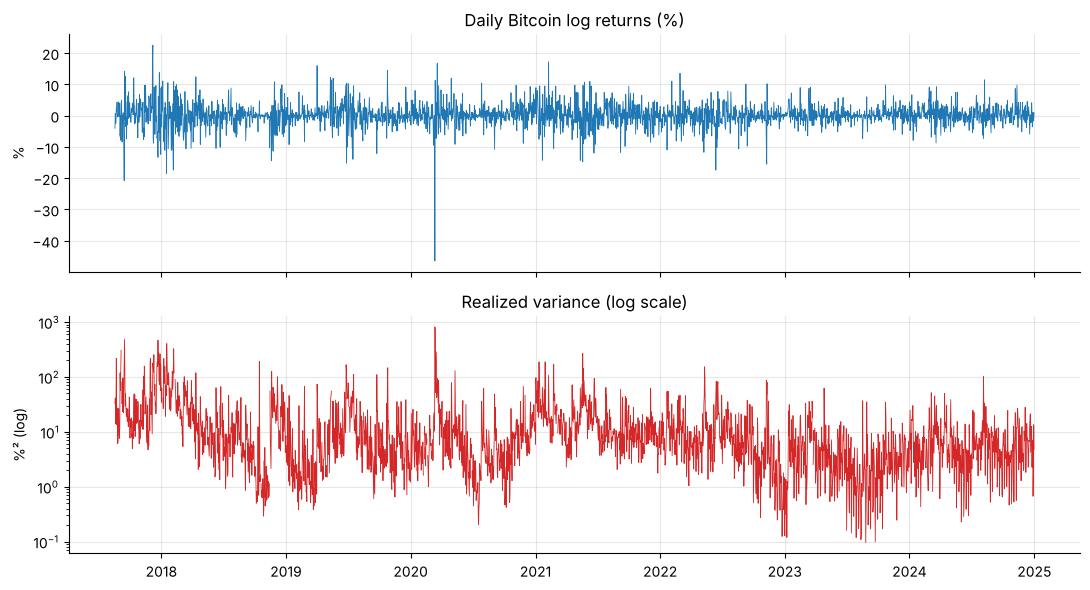

Mean (%)            0.1140
Std dev (%)         3.7117
Min (%)           -46.4730
Max (%)            22.5119
Skewness           -0.7499
Excess kurtosis    12.4743

Jarque-Bera = 17,712.9, p-value = 0.00e+00


In [3]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(train.index, train, lw=.6); ax[0].set_title("Daily Bitcoin log returns (%)"); ax[0].set_ylabel("%")
ax[1].plot(train.index, rv[:TRAIN_END], lw=.6, color="C3"); ax[1].set_yscale("log")
ax[1].set_title("Realized variance (log scale)"); ax[1].set_ylabel("%² (log)")
plt.tight_layout(); plt.show()

desc = pd.Series({"Mean (%)": train.mean(), "Std dev (%)": train.std(), "Min (%)": train.min(),
                  "Max (%)": train.max(), "Skewness": stats.skew(train),
                  "Excess kurtosis": stats.kurtosis(train)})
jb = stats.jarque_bera(train)
print(desc.to_string()); print(f"\nJarque-Bera = {jb.statistic:,.1f}, p-value = {jb.pvalue:.2e}")

**What the code does.** Plots returns and (log-scale) realized variance, then reports descriptive
statistics and the Jarque–Bera normality test.

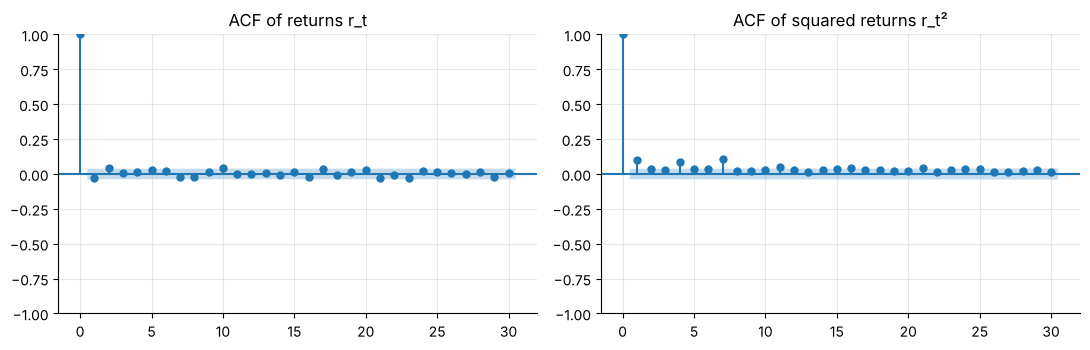

    Ljung-Box r (stat)      p  Ljung-Box r² (stat)     p 
10             19.7974 0.0312              93.8538 0.0000
20             29.6605 0.0755             120.9216 0.0000

ARCH-LM test on demeaned returns:
  lags=5: LM = 47.2, p-value = 5.16e-09
  lags=10: LM = 74.2, p-value = 6.82e-12


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
plot_acf(train, lags=30, ax=ax[0], title="ACF of returns r_t")
plot_acf(train**2, lags=30, ax=ax[1], title="ACF of squared returns r_t²")
plt.tight_layout(); plt.show()

lb_r = acorr_ljungbox(train, lags=[10, 20])
lb_r2 = acorr_ljungbox(train**2, lags=[10, 20])
arch_lm = {L: het_arch(train - train.mean(), nlags=L)[:2] for L in (5, 10)}
tab = pd.DataFrame({"Ljung-Box r (stat)": lb_r["lb_stat"], "p": lb_r["lb_pvalue"],
                    "Ljung-Box r² (stat)": lb_r2["lb_stat"], "p ": lb_r2["lb_pvalue"]})
print(tab.to_string())
print("\nARCH-LM test on demeaned returns:")
for L, (s, p) in arch_lm.items():
    print(f"  lags={L}: LM = {s:,.1f}, p-value = {p:.2e}")

**What the code does.** ACF of returns vs squared returns, Ljung–Box tests for serial dependence in
each, and Engle's ARCH-LM test (regress squared demeaned returns on their own lags).


### Interpretation — Task 1
**Key numbers (training sample, n = 2,693).** Mean return 0.11 %/day versus a standard deviation of 3.71 %/day;
skewness −0.75, **excess kurtosis 12.5**, worst day −46.5 %; Jarque–Bera rejects normality overwhelmingly.

**(a) Are daily returns predictable from their own history?** Essentially **no**. The ACF of `r_t` is tiny,
and the Ljung–Box test is only marginal (p = 0.031 at 10 lags, p = 0.076 at 20 lags). Any linear
predictability is very small compared with the 3.7 % daily noise and with the mean of 0.11 %, so it
is not something a risk manager could trade or size positions on. (With 2,693 observations even tiny autocorrelations can
reach "significance"; statistical significance is not economic usefulness.)

**(b) Is there volatility clustering?** **Yes, strongly.** Squared returns are highly autocorrelated
(ACF clearly positive across 30 lags; Ljung–Box on `r²` = 93.9 at 10 lags, p ≈ 0) and Engle's ARCH-LM
test rejects "no ARCH effects" (LM = 47.2 at 5 lags, 74.2 at 10 lags, p < 1e-8). The plots show it directly: calm
spells (e.g. 2023–24) alternate with violent ones (2017–18, March 2020, 2021). Direction
is nearly unpredictable, but **the size of the next move is partly predictable** — that is the forecasting opportunity.

**(c) What does an ARCH-LM rejection establish — and not?**
* *Establishes:* in-sample, squared (demeaned) returns are serially dependent, i.e. the conditional variance
  is time-varying and (statistically) related to past shocks.
* *Does not establish:* that a particular model (ARCH/GARCH) is the right one; how large or economically useful the
  predictability is; that it is **stable over time**; or that forecasts will be accurate **out of sample**. A
  rejection can also be driven by a few extreme observations or a structural break in the variance level.
  It is a necessary condition for volatility forecasting, not evidence of forecast quality.


---
# Part II — ARCH and GARCH
## Task 2 — Why does GARCH help?
Model: `r_t = μ + ε_t`, `ε_t = σ_t z_t`, with `z_t ~ N(0,1)`.
* ARCH(1): `σ²_t = ω + α ε²_{t−1}`
* GARCH(1,1): `σ²_t = ω + α ε²_{t−1} + β σ²_{t−1}`

Estimation is by Gaussian maximum likelihood on the **training sample**.

In [5]:
def fit(sample, p=1, q=1, dist="normal"):
    am = arch_model(sample, mean="Constant", vol="GARCH", p=p, q=q, dist=dist)
    return am.fit(disp="off", show_warning=False)

arch1 = fit(train, p=1, q=0)
garch_n = fit(train)

def param_table(res):
    return pd.DataFrame({"coef": res.params, "std err": res.std_err, "t": res.tvalues, "p-value": res.pvalues})

print("ARCH(1), Normal\n", param_table(arch1).to_string(), "\n")
print("GARCH(1,1), Normal\n", param_table(garch_n).to_string())

cmp = pd.DataFrame({m: {"Log-lik": x.loglikelihood, "AIC": x.aic, "BIC": x.bic}
                    for m, x in {"ARCH(1)": arch1, "GARCH(1,1)-N": garch_n}.items()}).T
print("\n", cmp.to_string())

a, b = garch_n.params["alpha[1]"], garch_n.params["beta[1]"]
w = garch_n.params["omega"]
pers = a + b
print(f"\nα̂ = {a:.4f} | β̂ = {b:.4f} | α̂+β̂ = {pers:.4f}")
print(f"Half-life of a volatility shock = ln(0.5)/ln(α̂+β̂) = {np.log(.5)/np.log(pers):.1f} days")
print(f"Unconditional variance ω/(1−α−β) = {w/(1-pers):.2f} %²  (sample var of returns = {train.var():.2f} %²)")

ARCH(1), Normal
             coef  std err      t  p-value
mu        0.1270   0.0686 1.8519   0.0640
omega    11.9022   1.2800 9.2988   0.0000
alpha[1]  0.1361   0.0459 2.9672   0.0030 

GARCH(1,1), Normal
            coef  std err       t  p-value
mu       0.1570   0.0663  2.3694   0.0178
omega    0.6578   0.2771  2.3739   0.0176
alpha[1] 0.0997   0.0423  2.3547   0.0185
beta[1]  0.8587   0.0447 19.2270   0.0000

                  Log-lik         AIC         BIC
ARCH(1)      -7,307.0578 14,620.1155 14,637.8108
GARCH(1,1)-N -7,164.5749 14,337.1498 14,360.7435

α̂ = 0.0997 | β̂ = 0.8587 | α̂+β̂ = 0.9583
Half-life of a volatility shock = ln(0.5)/ln(α̂+β̂) = 16.3 days
Unconditional variance ω/(1−α−β) = 15.79 %²  (sample var of returns = 13.78 %²)


**What the code does.** Fits ARCH(1) and GARCH(1,1) by Gaussian ML, tabulates coefficients with
standard errors, compares log-likelihood/AIC/BIC, and computes the persistence `α̂+β̂`, the
half-life `ln(0.5)/ln(α̂+β̂)` and the implied unconditional variance.


### Interpretation — Task 2
**Fit.** GARCH(1,1) beats ARCH(1) decisively: log-likelihood −7,164.6 vs −7,307.1, AIC 14,337 vs 14,620,
BIC 14,361 vs 14,638 (≈ 285 AIC points better for just one extra parameter). A single lag of the squared shock
cannot capture how long Bitcoin's volatility episodes last; the lagged variance term `β σ²_{t−1}` does that parsimoniously.

**Economic meaning of GARCH(1,1) (Normal):** `α̂ = 0.100`, `β̂ = 0.859`, `α̂ + β̂ = 0.958`.
* **Reaction to a new shock (α̂ ≈ 0.10).** Each unit of squared surprise adds ≈ 0.10 to tomorrow's variance.
  A 10 % surprise (ε² = 100) adds about 10 %² to the next-day variance — roughly two-thirds of the long-run level
  (≈ 15.8 %²). Risk reacts noticeably, but is not completely re-set by one day.
* **Persistence (β̂ ≈ 0.86; α̂ + β̂ ≈ 0.96).** Most of yesterday's variance carries over, so volatility is highly persistent:
  the half-life of a volatility shock is `ln(0.5)/ln(0.958) ≈ 16.3 days`. Bitcoin risk shocks fade over weeks, not days.
* Implied long-run variance `ω/(1−α−β) = 15.8 %²` (≈ 3.97 %/day), close to the sample variance 13.8 %², a sanity check that the model is consistent with the data.

**Significance.** Every key variance parameter is significant (ω p = 0.018, α p = 0.019, β t ≈ 19).

**Why this is not yet evidence of forecast accuracy.** (i) These are *in-sample* statistics: parameters are fitted to the same data
they are tested on. (ii) Significance says the true `α, β` are different from 0; it says nothing about the *size* of
the forecast errors — even a correct model leaves a lot of noise because the daily shock `z_t` is random. (iii) The variance is latent: we are
judging it only through noisy proxies. (iv) Parameters may drift (see Part VI), so what was true in 2017–2024 may not hold in 2025–26.
Only a genuine out-of-sample test (Part IV) answers "will it forecast accurately?".


---
# Part III — Does the conditional distribution matter?
## Task 3 — Normal vs standardized Student-t GARCH(1,1)
Two **separate** modelling choices: (i) the *variance recursion* (how σ²_t evolves) and (ii) the
*distribution of the innovation z_t* (Normal vs fat-tailed t with ν degrees of freedom).

GARCH(1,1), Student-t
            coef  std err       t  p-value
mu       0.0888   0.0421  2.1093   0.0349
omega    0.1304   0.0889  1.4669   0.1424
alpha[1] 0.0729   0.0112  6.4968   0.0000
beta[1]  0.9271   0.0152 61.1800   0.0000
nu       3.1832   0.1586 20.0764   0.0000

             Log-lik         AIC         BIC  alpha   beta  alpha+beta
GARCH-N -7,164.5749 14,337.1498 14,360.7435 0.0997 0.8587      0.9583
GARCH-t -6,831.3624 13,672.7248 13,702.2168 0.0729 0.9271      1.0000

Standardized residual excess kurtosis: Normal model = 13.51, t model = 16.89
Ljung-Box p-value on z² (10 lags): N = 0.855, t = 0.898


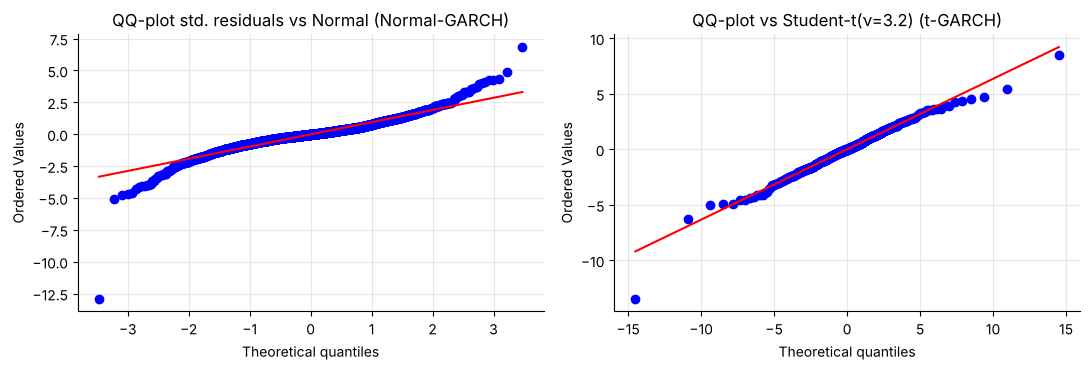

In [6]:
garch_t = fit(train, dist="t")
print("GARCH(1,1), Student-t\n", param_table(garch_t).to_string())

cmp3 = pd.DataFrame({m: {"Log-lik": x.loglikelihood, "AIC": x.aic, "BIC": x.bic,
                         "alpha": x.params["alpha[1]"], "beta": x.params["beta[1]"],
                         "alpha+beta": x.params["alpha[1]"] + x.params["beta[1]"]}
                     for m, x in {"GARCH-N": garch_n, "GARCH-t": garch_t}.items()}).T
print("\n", cmp3.to_string())

z_n = garch_n.std_resid.dropna(); z_t = garch_t.std_resid.dropna()
print(f"\nStandardized residual excess kurtosis: Normal model = {stats.kurtosis(z_n):.2f}, t model = {stats.kurtosis(z_t):.2f}")
print(f"Ljung-Box p-value on z² (10 lags): N = {acorr_ljungbox(z_n**2, lags=[10])['lb_pvalue'].iloc[0]:.3f}, "
      f"t = {acorr_ljungbox(z_t**2, lags=[10])['lb_pvalue'].iloc[0]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
stats.probplot(z_n, dist="norm", plot=ax[0]); ax[0].set_title("QQ-plot std. residuals vs Normal (Normal-GARCH)")
nu = garch_t.params["nu"]
stats.probplot(z_t, dist="t", sparams=(nu,), plot=ax[1]); ax[1].set_title(f"QQ-plot vs Student-t(ν={nu:.1f}) (t-GARCH)")
plt.tight_layout(); plt.show()

**What the code does.** Re-estimates GARCH(1,1) with standardized Student-t errors, compares fit
(log-lik/AIC/BIC), and checks the standardized residuals `z_t = ε_t/σ_t` with QQ-plots.


### Interpretation — Task 3
**Fit improves massively with Student-t errors:** log-likelihood −6,831.4 vs −7,164.6 (+333), AIC 13,672.7 vs 14,337.1,
BIC 13,702.2 vs 14,360.7, for a single extra parameter. Every criterion prefers the t.

**Degrees of freedom: ν̂ = 3.18 (s.e. 0.16).** This is extremely heavy-tailed (a Normal corresponds to ν → ∞; ν ≈ 3 means the variance is finite but the
fourth moment — kurtosis — is not). Extreme days such as −46 % are *not* freak events for this distribution. The QQ-plots tell the same story:
the standardized residuals of the Normal model leave the 45° line in both tails, whereas the t-GARCH residuals follow the t-quantile line well.
(The *sample* kurtosis of the t-model residuals, 16.9, is not comparable with a Normal's 3: a t₃ has infinite theoretical kurtosis.)

**Does it change the description of Bitcoin returns?** The *distribution* matters a lot for likelihood-based comparisons, tail probabilities,
VaR/Expected Shortfall and parameter estimates; the *variance recursion* barely changes: the clustering is captured in both
cases (Ljung–Box on `z²` p = 0.86 / 0.90 — no remaining ARCH). Keep the two choices separate:
* **Conditional variance recursion** → *how risk evolves* (GARCH(1,1) in both models).
* **Conditional distribution of z_t** → *how large the surprises relative to σ_t can be* (tails).

**Note on parameters.** Under the t, α̂ falls to 0.073 while β̂ rises to 0.927: the Normal model had to read extreme days as huge
variance jumps; the t attributes them to tail draws. **α̂ + β̂ = 1.000 — the estimate sits on the stationarity boundary** (the `arch` package
constrains α+β ≤ 1; this is an *IGARCH* outcome): shocks to variance never die out on average, the half-life is infinite and
there is no finite unconditional variance (ω is no longer significant, p = 0.14). Practically, forecasts behave like an exponentially weighted moving
average. Standard errors on the boundary are not reliable, a caveat we will carry into Task 6.


---
# Part IV — Forecasting a latent variable
## Task 4 — Expanding-window one-day-ahead GARCH-t forecasts
For every OOS date `d` (1 Jan 2025 … 31 Aug 2026):
1. estimate GARCH(1,1)-t on returns **strictly before** `d` (i.e. through `d−1`);
2. produce the one-step variance forecast `σ̂²_{d|d−1}`;
3. compare with `RV_d` once observed.

The same function also supports the **two-year rolling window** used later in Part VI
(window = `[d − 2 years, d − 1 day]`; for `d = 1 Jan 2025` this is exactly 1 Jan 2023 – 31 Dec 2024).
We store the parameters and the standard error of `α+β` (delta method using the full parameter
covariance: `Var(α̂+β̂) = Var(α̂)+Var(β̂)+2Cov(α̂,β̂)`), as needed by Task 6.

In [7]:
def window(d, mode):
    idx = r.index
    if mode == "expanding":
        return r[idx < d]
    return r[(idx >= d - pd.DateOffset(years=2)) & (idx < d)]

def garch_origin(d, mode):
    s = window(d, mode)
    res = fit(s, dist="t")
    h = res.forecast(horizon=1, reindex=False).variance.iloc[-1, 0]
    p, C = res.params, res.param_cov
    var_pers = C.loc["alpha[1]", "alpha[1]"] + C.loc["beta[1]", "beta[1]"] + 2 * C.loc["alpha[1]", "beta[1]"]
    return dict(date=d, h=h, alpha=p["alpha[1]"], beta=p["beta[1]"], pers=p["alpha[1]"] + p["beta[1]"],
                pers_se=np.sqrt(max(var_pers, 0)), nu=p["nu"], n_obs=len(s), conv=res.convergence_flag)

def run_garch(mode):
    out = Parallel(n_jobs=-1)(delayed(garch_origin)(d, mode) for d in oos_dates)
    return pd.DataFrame(out).set_index("date")

g_exp = run_garch("expanding")
print("Expanding GARCH-t done:", g_exp.shape, "| non-converged fits:", int((g_exp.conv != 0).sum()))
g_exp[["h", "alpha", "beta", "pers", "nu"]].describe().T

Expanding GARCH-t done: (608, 8) | non-converged fits: 0


,count,mean,std,min,25%,50%,75%,max
h,608.0000,7.1205,4.2421,2.7578,4.4542,6.0289,8.1897,37.1312
alpha,608.0000,0.0748,0.0014,0.0721,0.0736,0.0750,0.0757,0.0791
beta,608.0000,0.9252,0.0014,0.9209,0.9243,0.9250,0.9264,0.9279
pers,608.0000,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
nu,608.0000,3.1892,0.0110,3.1677,3.1827,3.1892,3.1975,3.2251


**What the code does.** `window()` picks the information set (all history before `d`, or only the
last two years). `garch_origin()` re-fits the model and returns the 1-step variance forecast plus the
parameters. We loop over all 608 OOS dates in parallel — about 600 separate estimations, which is
why this cell takes a few minutes.

                      MSE  QLIKE   Corr  Mean forecast  Mean RV  Mean fcst / Mean RV        N
GARCH-t expanding 48.6721 2.6120 0.3278         7.1205   5.3764               1.3244 608.0000


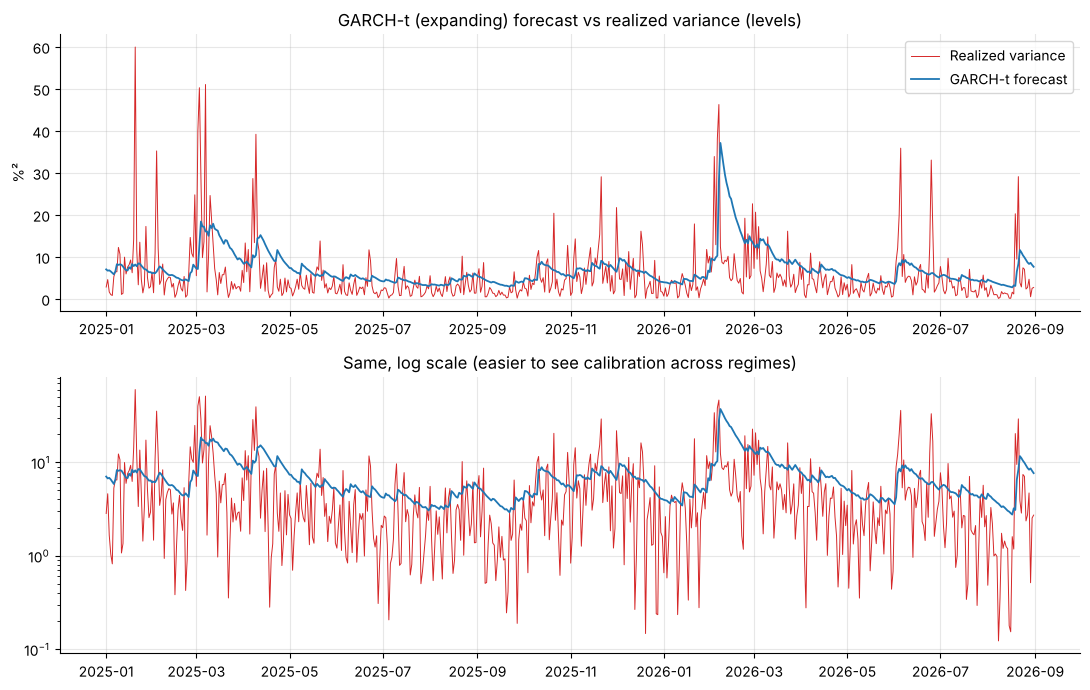

In [8]:
def evaluate(h, name):
    """MSE, QLIKE, correlation, mean levels — on dates where RV is observed."""
    d = pd.concat([h.rename("h"), rv.rename("rv")], axis=1).dropna()
    d = d[d.h > 0]
    mse = np.mean((d.rv - d.h) ** 2)
    qlike = np.mean(np.log(d.h) + d.rv / d.h)
    return pd.Series({"MSE": mse, "QLIKE": qlike, "Corr": d.h.corr(d.rv),
                      "Mean forecast": d.h.mean(), "Mean RV": d.rv.mean(),
                      "Mean fcst / Mean RV": d.h.mean() / d.rv.mean(), "N": len(d)}, name=name)

ev_garch_exp = evaluate(g_exp.h, "GARCH-t expanding")
print(ev_garch_exp.to_frame().T.to_string())

fig, ax = plt.subplots(2, 1, figsize=(11, 7))
ax[0].plot(rv[OOS_START:], lw=.7, color="C3", label="Realized variance"); ax[0].plot(g_exp.h, lw=1.3, label="GARCH-t forecast")
ax[0].set_title("GARCH-t (expanding) forecast vs realized variance (levels)"); ax[0].legend(); ax[0].set_ylabel("%²")
ax[1].plot(rv[OOS_START:], lw=.7, color="C3"); ax[1].plot(g_exp.h, lw=1.3); ax[1].set_yscale("log")
ax[1].set_title("Same, log scale (easier to see calibration across regimes)")
plt.tight_layout(); plt.show()

**What the code does.** `evaluate()` computes the three requested metrics plus average forecast vs
average RV (calibration) on dates with a valid RV. Then it plots forecasts against RV, in levels and
on a log axis.


### Interpretation — Task 4 (expanding-window GARCH-t vs RV)
| Metric | Value |
|---|---|
| MSE | 48.67 |
| QLIKE | 2.612 |
| Corr(ĥ, RV) | 0.328 |
| Mean forecast / Mean RV | 7.12 / 5.38 (≈ **+32 % too high**) |

**What each statistic says.**
* **MSE** — average squared distance in %² units. It is dominated by a few extreme-RV days (RV has a very long right tail), so it is noisy and rewards getting the
  *spikes* right.
* **QLIKE** — penalises *ratios* `RV/ĥ`, is scale-free across calm and turbulent periods and penalises under-prediction of risk
  more heavily than over-prediction. It is the preferred loss for variance forecasts because it ranks forecasts correctly even if RV is only a noisy proxy.
* **Correlation** — measures only whether forecasts *move with* RV; it is blind to level and scale.

**Why high correlation can still come with poor MSE/QLIKE.** Correlation is unaffected by adding a constant to the forecasts
or by multiplying them by any scale; MSE and QLIKE are affected by both. A forecast that tracks the *shape* of RV perfectly but is
systematically 30–80 % too large (or too small) still has a high correlation yet loses on MSE and QLIKE. Here
GARCH's average forecast (7.12 %²) is above average RV (5.38 %²): 2025–26 turned out calmer than the 2017–2024 history on which the model was fitted
(average RV in training ≈ 16 %²). The forecast is a bit too "nervous" on average — a **calibration** problem, not only a correlation problem.
Only ~0.33 correlation (≈ 11 % of the variance explained) also tells us that most day-to-day variation in RV remains unexplained.

**If GARCH forecasts high variance and tomorrow is quiet, was the forecast wrong? No — one observation proves nothing.**
`σ²_{t+1|t}` is a *conditional expectation* (the mean of a distribution of possible outcomes), not a promise. A high-variance forecast *should* occasionally be followed by a quiet day
(even a correct model produces many small realised squared returns; with a Normal, the median of `z²` is only ≈ 0.45). In addition, `σ²_{t+1|t}` is **latent**:
RV is only a noisy proxy for it, so a single gap between ĥ and RV mixes forecast error with measurement/sampling noise. Forecasts can only be judged **statistically,
across many days**: average loss, calibration (mean ĥ vs mean RV, ratio `RV/ĥ` ≈ 1 on average), and tests such as Diebold–Mariano for comparing models.


---
# Part V — A simple realized-variance benchmark
## Task 5 — RV-OLS: `RV_{t+1} = a + b·RV_t + u_{t+1}`
Estimated on the training sample (pairs where both RV values exist), with HAC (Newey–West) standard
errors because RV is persistent and heteroskedastic. Then forecasts over the same OOS dates, using
only pairs whose *target* date is before the forecast date.

*Missing-RV rule:* if `RV_{d−1}` is missing, the latest available earlier RV is used as the predictor
(the only information a forecaster would actually have). Evaluation always uses valid `RV_d`.

In [9]:
HAC_LAGS = 7   # one week of daily data; a conventional choice, no search performed

rv_lag = rv.shift(1)                       # RV_{t-1}, aligned with target RV_t
rv_lag_filled = rv.ffill().shift(1)        # predictor available at forecast origin
pairs = pd.concat([rv.rename("y"), rv_lag.rename("x")], axis=1).dropna()

tr = pairs[:TRAIN_END]
ols_train = sm.OLS(tr.y, sm.add_constant(tr.x)).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
print(ols_train.summary().tables[1])
print(f"\nIn-sample R² = {ols_train.rsquared:.3f}  (N = {int(ols_train.nobs)})")
print(f"Correlation(RV_t, RV_t-1) = {tr.y.corr(tr.x):.3f}")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.3104      0.823      8.879      0.000       5.697       8.924
x              0.5483      0.044     12.536      0.000       0.463       0.634

In-sample R² = 0.294  (N = 2636)
Correlation(RV_t, RV_t-1) = 0.542


negative RV-OLS forecasts (expanding): 0
                      MSE  QLIKE   Corr  Mean forecast  Mean RV  Mean fcst / Mean RV        N
GARCH-t expanding 48.6721 2.6120 0.3278         7.1205   5.3764               1.3244 608.0000
RV-OLS expanding  58.0697 2.7528 0.4290         9.7645   5.3764               1.8162 608.0000


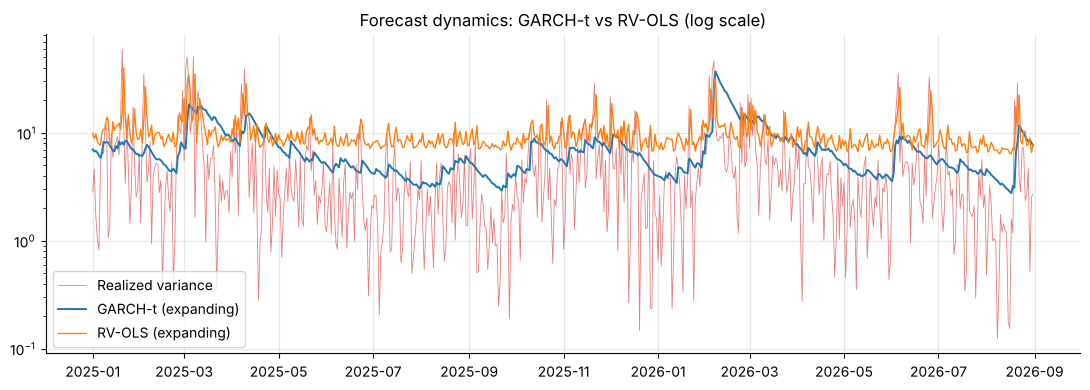


Std. dev. of forecasts: GARCH = 4.24 | RV-OLS = 3.8 | RV = 6.83
Day-to-day forecast change std (smoothness): GARCH = 1.1 | RV-OLS = 4.04


In [10]:
def ols_origin(d, mode):
    idx = pairs.index
    mask = idx < d if mode == "expanding" else (idx >= d - pd.DateOffset(years=2)) & (idx < d)
    s = pairs[mask]
    m = sm.OLS(s.y, sm.add_constant(s.x)).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
    a_, b_ = m.params["const"], m.params["x"]
    lo, hi = m.conf_int().loc["x"]
    return dict(date=d, h=a_ + b_ * rv_lag_filled[d], a=a_, b=b_, b_lo=lo, b_hi=hi, b_t=m.tvalues["x"], n_obs=len(s))

def run_ols(mode):
    return pd.DataFrame([ols_origin(d, mode) for d in oos_dates]).set_index("date")

o_exp = run_ols("expanding")
print("negative RV-OLS forecasts (expanding):", int((o_exp.h <= 0).sum()))
ev_ols_exp = evaluate(o_exp.h, "RV-OLS expanding")

comp5 = pd.concat([ev_garch_exp, ev_ols_exp], axis=1).T
print(comp5.to_string())

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(rv[OOS_START:], lw=.6, color="C3", alpha=.6, label="Realized variance")
ax.plot(g_exp.h, lw=1.4, label="GARCH-t (expanding)"); ax.plot(o_exp.h, lw=1.0, label="RV-OLS (expanding)")
ax.set_yscale("log"); ax.legend(); ax.set_title("Forecast dynamics: GARCH-t vs RV-OLS (log scale)")
plt.tight_layout(); plt.show()

print("\nStd. dev. of forecasts: GARCH =", round(g_exp.h.std(), 2), "| RV-OLS =", round(o_exp.h.std(), 2),
      "| RV =", round(rv[OOS_START:].std(), 2))
print("Day-to-day forecast change std (smoothness): GARCH =", round(g_exp.h.diff().std(), 2),
      "| RV-OLS =", round(o_exp.h.diff().std(), 2))

**What the code does.** Regresses `RV_t` on `RV_{t−1}` (HAC errors), reports `b̂`, its significance and
R². Then `ols_origin()` repeats the estimation at each OOS origin with the information set allowed,
forecasts `â + b̂·RV_{d−1}`, and we compare with GARCH on the *same* dates and metrics.

### Formal test of equal predictive accuracy (Diebold–Mariano)
Differences in average loss can be luck. The DM test regresses the loss differential
`L_A,t − L_B,t` on a constant with HAC errors; a significantly negative constant means A has lower loss.

In [11]:
def loss_series(h, kind):
    d = pd.concat([h.rename("h"), rv.rename("rv")], axis=1).dropna()
    d = d[d.h > 0]
    return (d.rv - d.h) ** 2 if kind == "MSE" else np.log(d.h) + d.rv / d.h

def dm(hA, hB, kind):
    la, lb = loss_series(hA, kind), loss_series(hB, kind)
    dd = (la - lb).dropna()
    m = sm.OLS(dd, np.ones(len(dd))).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
    return pd.Series({"mean loss diff (A−B)": dd.mean(), "t-stat": m.tvalues.iloc[0], "p-value": m.pvalues.iloc[0]})

dm_tab = pd.DataFrame({k: dm(g_exp.h, o_exp.h, k) for k in ("MSE", "QLIKE")}).T
print("DM test, A = GARCH-t expanding, B = RV-OLS expanding (negative ⇒ GARCH better)")
print(dm_tab.to_string())

DM test, A = GARCH-t expanding, B = RV-OLS expanding (negative ⇒ GARCH better)
       mean loss diff (A−B)  t-stat  p-value
MSE                 -9.3976 -1.5762   0.1150
QLIKE               -0.1407 -5.5757   0.0000



### Interpretation — Task 5 (GARCH-t vs RV-OLS, expanding)
**The regression.** `b̂ = 0.548` (HAC s.e. 0.044, t = 12.5, p ≈ 0), `â = 7.31`, in-sample **R² = 0.29**. About 55 % of
today's realised-variance deviation is still present tomorrow (an AR(1) half-life of only ≈ 1.2 days — fast mean reversion toward the intercept-implied level). The model has a significant but modest explanatory power.

**OOS comparison (same 608 dates, same metrics):**
| Model | MSE | QLIKE | Corr | Mean forecast |
|---|---|---|---|---|
| GARCH-t (expanding) | **48.67** | **2.612** | 0.328 | 7.12 |
| RV-OLS (expanding) | 58.07 | 2.753 | **0.429** | 9.76 |
| (Mean RV) | | | | 5.38 |

* GARCH-t wins on MSE and QLIKE; RV-OLS wins on correlation. This is exactly the correlation-vs-calibration point above: the regression tracks RV's *movements* better but its intercept
  (estimated when volatility was much higher, mean RV ≈ 16) makes forecasts **82 % too high** on average.
* **Diebold–Mariano:** the QLIKE advantage of GARCH is highly significant (mean loss difference −0.14, t = −5.6), while the MSE advantage (−9.4) is **not** significant (p = 0.115): MSE is dominated by a few spike days, so it
  cannot separate the models statistically.

**Dynamics of the forecasts.** RV-OLS is a one-lag filter `a + b·RV_{t}`: it jumps with every noisy RV observation (std of daily forecast changes 4.04) — a single spike
day moves tomorrow's forecast, and then it is gone. GARCH combines the last shock **and** the entire past through `σ²_{t−1}`, so it evolves
smoothly (std of daily changes 1.10) and moves into and out of high-volatility episodes gradually. In that sense GARCH is **more flexible in how it
uses history** (long memory) but **less jumpy**. The plots show it: GARCH follows the slow-moving volatility regime; RV-OLS follows the noise. This
flexibility helped on QLIKE, but it didn't help dramatically on MSE and it didn't improve correlation. Flexibility only turns into accuracy when
the extra structure is actually stable and relevant; here it brings a moderate, metric-dependent gain.

**Two different questions — keep them apart.**
1. *Does today's RV contain statistically significant information about tomorrow's RV?* **Yes**: t = 12.5, R² = 0.29.
2. *Does the resulting model forecast accurately enough to be useful?* **Only moderately**: OOS correlations are 0.33–0.43 (so roughly 10–18 % of RV variation explained),
   and the forecast errors are large relative to the average RV (RMSE ≈ 7 %² against a mean of 5.4 %²).

**Why a significant coefficient doesn't guarantee good OOS performance.** A t-statistic measures how precisely `b` is estimated, not how much unexplained noise remains
(with 2,600 observations even a weak relation is "highly significant"). The estimated relation can also change after the training period (the level of
volatility fell; we will see `b̂` drift to ≈ 0.35 in Part VI), outliers dominate squared-error losses, and in-sample fit is optimistic by construction.


---
# Part VI — Does distant Bitcoin history still help?
## Task 6 — Two-year rolling estimation and parameter stability
Same OOS dates, but each model is estimated on the **most recent two years only** and the window
slides forward one day at a time.

In [12]:
g_roll = run_garch("rolling")
o_roll = run_ols("rolling")
print("window sizes: GARCH", g_roll.n_obs.min(), "-", g_roll.n_obs.max(), "| non-converged:", int((g_roll.conv != 0).sum()))
print("negative RV-OLS rolling forecasts:", int((o_roll.h <= 0).sum()))

evs = pd.concat([ev_garch_exp, evaluate(g_roll.h, "GARCH-t rolling 2y"),
                 ev_ols_exp, evaluate(o_roll.h, "RV-OLS rolling 2y")], axis=1).T
print(evs.to_string())

window sizes: GARCH 730 - 731 | non-converged: 0
negative RV-OLS rolling forecasts: 0
                       MSE  QLIKE   Corr  Mean forecast  Mean RV  Mean fcst / Mean RV        N
GARCH-t expanding  48.6721 2.6120 0.3278         7.1205   5.3764               1.3244 608.0000
GARCH-t rolling 2y 47.0313 2.6151 0.2938         6.6226   5.3764               1.2318 608.0000
RV-OLS expanding   58.0697 2.7528 0.4290         9.7645   5.3764               1.8162 608.0000
RV-OLS rolling 2y  38.9814 2.5902 0.4215         5.9746   5.3764               1.1113 608.0000


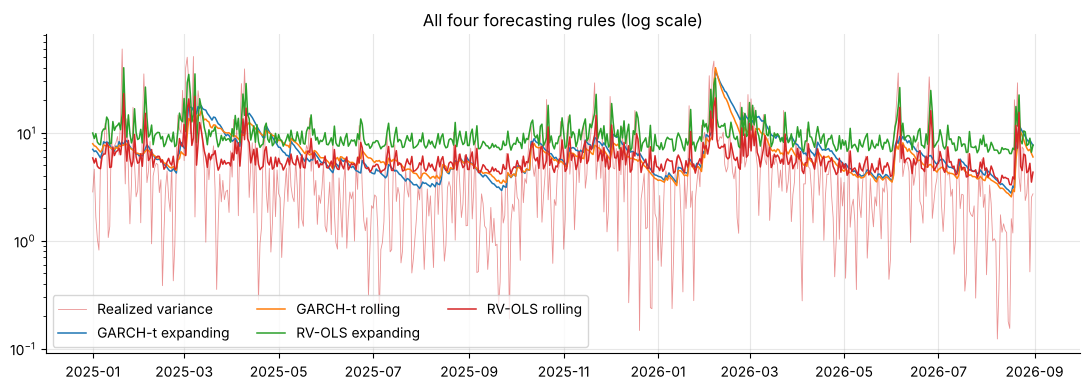

DM tests (A − B; negative ⇒ A better)
                               mean loss diff (A−B)  t-stat  p-value
GARCH roll vs GARCH exp MSE                 -1.6408 -0.9333   0.3507
                        QLIKE                0.0031  0.3890   0.6973
OLS roll vs OLS exp     MSE                -19.0883 -7.9523   0.0000
                        QLIKE               -0.1625 -8.1080   0.0000
GARCH roll vs OLS roll  MSE                  8.0499  1.7861   0.0741
                        QLIKE                0.0249  1.6223   0.1047


In [13]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(rv[OOS_START:], lw=.6, color="C3", alpha=.5, label="Realized variance")
for h_, lab in [(g_exp.h, "GARCH-t expanding"), (g_roll.h, "GARCH-t rolling"),
                (o_exp.h, "RV-OLS expanding"), (o_roll.h, "RV-OLS rolling")]:
    ax.plot(h_, lw=1.1, label=lab)
ax.set_yscale("log"); ax.legend(ncol=3); ax.set_title("All four forecasting rules (log scale)")
plt.tight_layout(); plt.show()

dm_rows = {}
for lab, A, B in [("GARCH roll vs GARCH exp", g_roll.h, g_exp.h), ("OLS roll vs OLS exp", o_roll.h, o_exp.h),
                  ("GARCH roll vs OLS roll", g_roll.h, o_roll.h)]:
    for k in ("MSE", "QLIKE"):
        dm_rows[(lab, k)] = dm(A, B, k)
print("DM tests (A − B; negative ⇒ A better)")
print(pd.DataFrame(dm_rows).T.to_string())

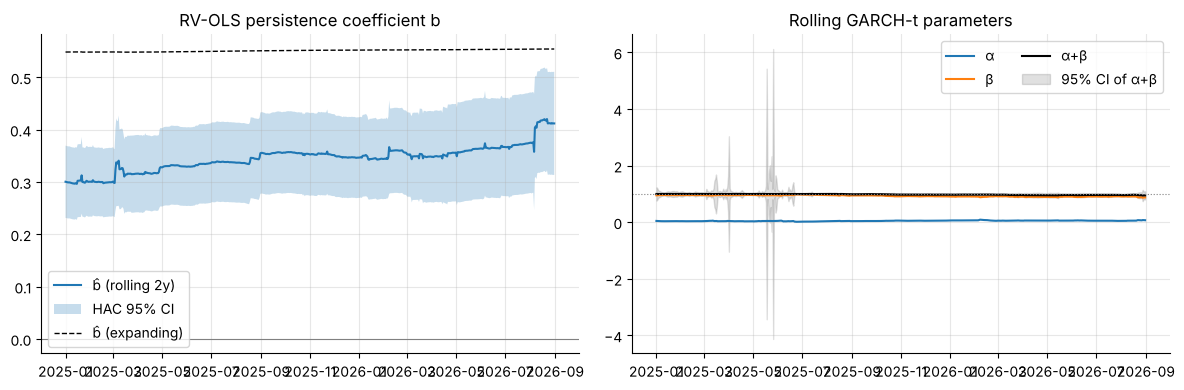

RV-OLS rolling b̂: min 0.296 | median 0.348 | max 0.420
Share of windows with HAC 95% CI strictly above 0: 100.0%
Rolling GARCH α+β: min 0.945 | median 0.978 | max 1.000
Share of windows with α+β > 0.99: 43.6% | 95% CI upper bound ≥ 1: 100.0%
Rolling GARCH ν: min 3.0 | median 3.8 | max 4.5


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(o_roll.b, label="b̂ (rolling 2y)"); ax[0].fill_between(o_roll.index, o_roll.b_lo, o_roll.b_hi, alpha=.25, label="HAC 95% CI")
ax[0].plot(o_exp.b, ls="--", color="k", lw=1, label="b̂ (expanding)"); ax[0].axhline(0, color="grey", lw=.8)
ax[0].set_title("RV-OLS persistence coefficient b"); ax[0].legend()
ax[1].plot(g_roll.alpha, label="α"); ax[1].plot(g_roll.beta, label="β"); ax[1].plot(g_roll.pers, label="α+β", color="k")
ax[1].fill_between(g_roll.index, g_roll.pers - 1.96 * g_roll.pers_se, g_roll.pers + 1.96 * g_roll.pers_se, color="k", alpha=.12, label="95% CI of α+β")
ax[1].axhline(1, color="grey", lw=.8, ls=":"); ax[1].set_title("Rolling GARCH-t parameters"); ax[1].legend(ncol=2)
plt.tight_layout(); plt.show()

print("RV-OLS rolling b̂: min %.3f | median %.3f | max %.3f" % (o_roll.b.min(), o_roll.b.median(), o_roll.b.max()))
print("Share of windows with HAC 95%% CI strictly above 0: %.1f%%" % (100 * (o_roll.b_lo > 0).mean()))
print("Rolling GARCH α+β: min %.3f | median %.3f | max %.3f" % (g_roll.pers.min(), g_roll.pers.median(), g_roll.pers.max()))
print("Share of windows with α+β > 0.99: %.1f%% | 95%% CI upper bound ≥ 1: %.1f%%" %
      (100 * (g_roll.pers > .99).mean(), 100 * ((g_roll.pers + 1.96 * g_roll.pers_se) >= 1).mean()))
print("Rolling GARCH ν: min %.1f | median %.1f | max %.1f" % (g_roll.nu.min(), g_roll.nu.median(), g_roll.nu.max()))

**What the code does.** Re-runs both models on the 2-year window, evaluates all four rules, runs DM
tests, and plots the rolling `b̂` with its HAC confidence band and the rolling GARCH `α, β, α+β` (with
the delta-method band for persistence). We summarise the *distribution* of the estimates rather than
cherry-picking a "best" window, as the case instructs.


### Interpretation — Task 6 (two-year rolling window)
**(a) Expanding vs rolling.**
| Rule | MSE | QLIKE | Corr | Mean forecast (Mean RV = 5.38) |
|---|---|---|---|---|
| GARCH-t expanding | 48.67 | 2.612 | 0.328 | 7.12 |
| GARCH-t rolling 2y | 47.03 | 2.615 | 0.294 | 6.62 |
| RV-OLS expanding | 58.07 | 2.753 | 0.429 | 9.76 |
| RV-OLS rolling 2y | **38.98** | **2.590** | 0.422 | 5.97 |

* **GARCH hardly cares about the window**: differences are insignificant (DM p = 0.35 for MSE, 0.70 for QLIKE) — its variance recursion re-anchors itself daily.
* **RV-OLS benefits enormously from forgetting distant history** (MSE 58.1 → 39.0, QLIKE 2.753 → 2.590; DM t ≈ −8). Almost all of the gain is **calibration**: the
  average forecast drops from 9.76 to 5.97, almost matching mean RV; correlation is unchanged (0.43 → 0.42).
* The ranking changes: with the expanding window GARCH is better on MSE/QLIKE; with the rolling window RV-OLS has the lowest MSE and QLIKE. However, the
  rolling RV-OLS vs rolling GARCH difference is **not statistically significant at 5 %** (DM p = 0.074 on MSE, 0.105 on QLIKE). So honest conclusion: the two are close on the rolling window.

**(b) Is the RV persistence coefficient stable?** Its **sign and significance** are very stable: the HAC 95 % interval is strictly above zero in **100 %** of the rolling windows.
Its **size** is not: `b̂` ranges from 0.30 to 0.42 (median 0.35), well below the 0.55 estimated on the 2017–2024 sample. So today's RV *always* carries information about tomorrow's, but the
strength of that link differs across the history, and by 2025–26 it is weaker than the older sample suggested.

**(c) How stable is GARCH persistence?** `α̂+β̂` ranges from 0.945 to 1.000 (median 0.978); it is above 0.99 in 44 % of the windows, and `ν̂` moves between about 3.0 and 4.5 (median 3.8). Estimates
close to one imply: (i) very slow decay of volatility shocks (half-life ≈ 31 days at 0.978, ≈ 69 days at 0.99, infinite at 1); (ii) as α+β → 1 (IGARCH), forecasts at long horizons do not revert to a long-run variance
and the model behaves like an EWMA/RiskMetrics filter; (iii) the parameter is **hard to pin down**: our delta-method 95 % band (using `Var(α̂)+Var(β̂)+2Cov(α̂,β̂)`) contains 1 in all windows, so
we cannot distinguish "0.95" from "unit root". The band itself is unreliable near the boundary, since the estimate is constrained at 1. Apparent unit-root persistence can also be an artefact of shifts in the
level of volatility that the model reads as persistence.

**(d) What does a ranking that changes with the window suggest?** Distant history is **not free**: for a model that relies on a fixed level/slope (RV-OLS) it can be actively harmful, because volatility was structurally higher in
2017–2022 than in 2025–26. A model with a self-updating variance state (GARCH) is more robust to the choice of information set. Practical lesson: judge the *forecasting rule* (model + information set), and treat the window as part of the model.

**(e) Does this prove a structural break?** **No.** (1) We never *tested* for a break (no Chow/Bai–Perron-type test) and the rolling estimates vary naturally from window to window through sampling error alone — particularly with heavy tails. (2) Differences between rules in a ~600-day OOS sample are often not statistically significant (see DM).
(3) Alternative explanations: slowly moving volatility level (regimes), time-varying parameters, a misspecified AR(1)/GARCH structure (e.g. long memory), and a few outliers entering/leaving windows. The results
are *consistent with* an evolving volatility environment and say that old data should be used with caution, but they don't identify a break date or mechanism.


---
# Part VII — Recommendation to the risk manager


### Answers to the risk manager's questions
* **Is there a meaningful predictable component?** Yes, but modest. Direction is essentially unpredictable; volatility clusters (ARCH-LM p < 1e-8) and today's RV is significantly related to tomorrow's. Out of sample, forecast correlations with RV are only 0.29–0.43, so most day-to-day variation is unexplained.
* **Does GARCH give economically sensible dynamics?** Yes: reactions to shocks of α ≈ 0.07–0.10, high persistence (≈ 0.96 Normal, ≈ 1 with t), half-lives of weeks. That matches a market where volatility episodes are long-lived.
* **Student-t vs Normal?** The t is clearly preferred (ΔAIC ≈ −664; ν̂ ≈ 3.2): Bitcoin's tails are extremely heavy. This matters most for tail measures (VaR/ES), less for the variance recursion itself.
* **What does the RV comparison say about forecast quality?** Useful but far from perfect. GARCH-t beats the expanding RV-OLS on MSE and (significantly) QLIKE, but both are poorly calibrated on average over this OOS period (GARCH +32 %, expanding OLS +82 %) because 2025–26 was calmer than the history used to fit them.
* **Dynamics: GARCH vs RV-OLS.** GARCH is smooth and long-memory; RV-OLS is a jumpy one-lag filter. The extra flexibility is economically sensible (position sizes shouldn't jump with each noisy RV print) and improves QLIKE against the expanding OLS, but it doesn't deliver large or uniform OOS gains.
* **Significance vs OOS performance.** A t-stat of 12.5 on `b` and highly significant GARCH parameters coexisted with only moderate OOS accuracy and unstable parameters. Judge models by OOS loss (QLIKE/MSE, DM tests), not by in-sample significance.
* **Expanding vs rolling.** Rolling (two years) is preferred: it never hurts GARCH significantly and rescues RV-OLS (MSE −33 %, QLIKE −0.16). Distant history is of little use and may mislead.
* **What can the forecasts be used for?** Relative risk scaling (volatility targeting, position sizing, risk limits, margin buffers) and as an input to VaR/ES — together with a heavy-tailed distribution. Not for precise day-by-day point predictions or timing crashes.
* **Main limitation / uncertainty.** (1) Latent variance measured by a noisy proxy; (2) unstable parameters and near-unit-root persistence; (3) conclusions rest on ~600 OOS days in one regime, and many differences are not statistically significant (e.g. rolling GARCH vs rolling RV-OLS, p ≈ 0.07–0.10); (4) the heavy tails mean rare large shocks will still surprise any forecast.

### Executive recommendation (≤ 150 words)
**Implement tomorrow:** a Student-t GARCH(1,1) re-estimated daily on a two-year rolling window, with the rolling RV regression as a cross-check. Use it to scale positions and set risk limits as volatility rises and falls, not as a precise point forecast or crash predictor. Evidence: volatility is clearly predictable in-sample, but out-of-sample forecast correlation with realized variance is only 0.3–0.4, so most daily variation remains unexplained. GARCH beat the expanding regression on QLIKE; the rolling regression scored best but not significantly better than GARCH, and its forecasts jump daily. Estimated persistence is near one, so shocks fade slowly. **Confidence:** moderate for the direction and relative level of risk, low for precise levels. Re-evaluate monthly, keep buffers in limits, and watch for regime shifts.
